In [1]:
!cp /kaggle/input/datamatcanbang1/detr_resume_checkpoint.pth /kaggle/working/
!cp /kaggle/input/datamatcanbang1/training_log.json /kaggle/working/
!cp -r /kaggle/input/datamatcanbang1/best_model /kaggle/working/
!cp /kaggle/input/datamatcanbang1/training_log.json /kaggle/working/

In [2]:
import json
import matplotlib.pyplot as plt
import matplotlib
import os

matplotlib.rcParams.update(matplotlib.rcParamsDefault)

log_file = "/kaggle/input/datamatcanbang1/training_log.json"
with open(log_file, "r") as f:
    history = json.load(f)

# === Thêm val_recall vào metric list ===
metrics = [
    ("train_loss",     "Training Loss Convergence", "#FF5733"),
    ("val_map",        "Validation mAP per Epoch", "#D2691E"),
    ("val_map50",      "mAP50",                     "#FF8C00"),
    ("val_map75",      "mAP75",                     "#CD853F"),
    ("f1",             "F1 Score",                  "#00AEEF"),
    ("val_ap_small",   "AP Small",                  "#8A2BE2"),
    ("val_ap_medium",  "AP Medium",                 "#9370DB"),
    ("val_ap_large",   "AP Large",                  "#9400D3"),
    ("val_precision",  "Precision",                 "#28a745"),   # xanh lá như bạn yêu cầu
    ("val_recall",     "Recall",                    "#FF4C4C")    # màu đỏ cam giống biểu đồ mẫu
]

os.makedirs("charts", exist_ok=True)

# ==============================
# STYLE GIỐNG HÌNH MẪU
# ==============================
for key, title, color in metrics:
    if key not in history:
        continue

    y = history[key]
    x = list(range(len(y)))

    best_value = max(y)
    best_epoch = y.index(best_value)

    plt.figure(figsize=(12, 8))

    # Fill dưới đường — nhạt hơn 70%
    plt.fill_between(x, y, color=color, alpha=0.22)

    # Đường line + marker
    plt.plot(x, y, marker='s', linewidth=3, color=color, label=title)

    # Đánh dấu best point
    plt.scatter(best_epoch, best_value, color="red", s=150, marker="*", label=f"Best: {best_value:.4f}")

    # Title lớn kiểu bold
    plt.title(title + " Evolution During Training", fontsize=22, fontweight="bold")

    # Label trục
    plt.xlabel("Epoch", fontsize=16, fontweight="bold")
    plt.ylabel(title.replace("Validation ", ""), fontsize=16, fontweight="bold")

    # Lưới dashed nhẹ
    plt.grid(True, linestyle='--', alpha=0.5)

    # Viền trục đậm giống hình mẫu
    ax = plt.gca()
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(3)
        ax.spines[spine].set_color("black")

    # Tắt viền trên + phải
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    # Legend
    plt.legend(fontsize=14)

    plt.tight_layout()
    plt.ylim(0, 1)

    # Save file từng hình
    plt.savefig(f"charts/{key}.png", dpi=200)
    plt.close()

print("Đã xuất tất cả biểu đồ với style chuẩn theo mẫu + thêm recall + precision xanh lá!")


Đã xuất tất cả biểu đồ với style chuẩn theo mẫu + thêm recall + precision xanh lá!


In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib
import os

matplotlib.rcParams.update(matplotlib.rcParamsDefault)

log_file = "/kaggle/input/datamatcanbang1/training_log.json"
with open(log_file, "r") as f:
    history = json.load(f)

# === Thêm val_recall vào metric list ===
metrics = [
    ("train_loss",     "Training Loss Convergence", "#FF5733"),
    ("val_map",        "Validation per Epoch", "#D2691E"),
    ("val_map50",      "mAP50",                     "#FF8C00"),
    ("val_map75",      "mAP75",                     "#CD853F"),
    ("f1",             "F1 Score",                  "#00AEEF"),
    ("val_ap_small",   "AP Small",                  "#8A2BE2"),
    ("val_ap_medium",  "AP Medium",                 "#9370DB"),
    ("val_ap_large",   "AP Large",                  "#9400D3"),
    ("val_precision",  "Precision",                 "#28a745"),   # xanh lá như bạn yêu cầu
    ("val_recall",     "Recall",                    "#FF4C4C")    # màu đỏ cam giống biểu đồ mẫu
]

os.makedirs("charts", exist_ok=True)

# ==============================
# STYLE GIỐNG HÌNH MẪU
# ==============================
for key, title, color in metrics:
    if key not in history:
        continue

    y = history[key]
    x = list(range(len(y)))

    best_value = max(y)
    best_epoch = y.index(best_value)

    plt.figure(figsize=(12, 8))

    # Fill dưới đường — nhạt hơn 70%
    plt.fill_between(x, y, color=color, alpha=0.22)

    # Đường line + marker
    plt.plot(x, y, marker='s', linewidth=3, color=color, label=title)

    # Đánh dấu best point
    plt.scatter(best_epoch, best_value, color="red", s=150, marker="*", label=f"Best: {best_value:.4f}")

    # Title lớn kiểu bold
    plt.title(title + " Evolution During Training", fontsize=22, fontweight="bold")

    # Label trục
    plt.xlabel("Epoch", fontsize=16, fontweight="bold")
    plt.ylabel(title.replace("Validation ", ""), fontsize=16, fontweight="bold")

    # Lưới dashed nhẹ
    plt.grid(True, linestyle='--', alpha=0.5)

    # Viền trục đậm giống hình mẫu
    ax = plt.gca()
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(3)
        ax.spines[spine].set_color("black")

    # Tắt viền trên + phải
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    # Legend
    plt.legend(fontsize=14)

    plt.tight_layout()
    plt.ylim(0, 1)

    # Save file từng hình
    plt.savefig(f"charts/{key}.png", dpi=200)
    plt.close()

print("Đã xuất tất cả biểu đồ với style chuẩn theo mẫu + thêm recall + precision xanh lá!")


Đã xuất tất cả biểu đồ với style chuẩn theo mẫu + thêm recall + precision xanh lá!


In [ ]:
# 1. CÀI ĐẶT THƯ VIỆN
!pip install -q torch torchvision torchaudio pycocotools matplotlib tqdm
!pip install -q torchmetrics transformers seaborn timm scipy

In [3]:
import os
import json
import time
import random
import numpy as np
import cv2
import torch
import torch.nn as nn
import albumentations as A
import warnings
from PIL import Image
from tqdm.notebook import tqdm
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from transformers import DeformableDetrImageProcessor, DeformableDetrForObjectDetection
from torchmetrics.detection import MeanAveragePrecision

# Tắt cảnh báo
warnings.filterwarnings("ignore")
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

2025-12-09 01:54:18.509186: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1765245258.695547      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1765245258.756557      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

In [4]:
# ================= 1. CẬP NHẬT LẠI CONFIG (BỊ THIẾU DÒNG THỜI GIAN) =================
CONFIG = {
    'MODEL_ID': "SenseTime/deformable-detr", 
    'IMG_SIZE': 480,         
    'EPOCHS': 50,            
    'BATCH_SIZE': 4,         
    'ACCUMULATION_STEPS': 4, 
    'LR': 1e-4,
    'LR_BACKBONE': 1e-5,
    'WEIGHT_DECAY': 1e-4,
    
    # --- DÒNG BỊ THIẾU GÂY RA LỖI KEY ERROR ---
    'MAX_TIME_SEC': 11.5 * 3600, # 11.5 tiếng (đổi ra giây)
    # ------------------------------------------

    "TRAIN_IMG_DIR": "/kaggle/input/traffic-object/ImBalanced-Data/ImBalanced-Data/train",
    "TRAIN_ANN_FILE": "/kaggle/input/traffic-object/ImBalanced-Data/ImBalanced-Data/annotations/instances_train.json",
    "VAL_IMG_DIR":   "/kaggle/input/traffic-object/ImBalanced-Data/ImBalanced-Data/val",
    "VAL_ANN_FILE":  "/kaggle/input/traffic-object/ImBalanced-Data/ImBalanced-Data/annotations/instances_val.json",
    
    "SAVE_DIR": "/kaggle/working/",
    "CHECKPOINT_FILE": "/kaggle/working/detr_resume_checkpoint.pth",
    "BEST_MODEL_DIR": "/kaggle/working/best_model/"
}

In [5]:
processor = DeformableDetrImageProcessor.from_pretrained(CONFIG['MODEL_ID'], do_resize=False, do_pad=False)

class CocoDataset(Dataset):
    def __init__(self, root, ann_file, processor, train=True):
        self.root = root
        self.processor = processor
        self.train = train
        with open(ann_file) as f: self.coco = json.load(f)
        self.images = {img['id']: img for img in self.coco['images']}
        self.annotations = {img_id: [] for img_id in self.images.keys()}
        for ann in self.coco['annotations']: self.annotations[ann['image_id']].append(ann)
        self.ids = list(self.images.keys())
        
        # Transform với size 480
        self.transform = A.Compose([
            A.Resize(CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"]),
            A.HorizontalFlip(p=0.5) if train else A.NoOp(),
            A.RandomBrightnessContrast(p=0.2) if train else A.NoOp(),
            A.ColorJitter(p=0.3) if train else A.NoOp(),
        ], bbox_params=A.BboxParams(format='coco', label_fields=['category_ids'], min_visibility=0.1))

    def __getitem__(self, idx):
        img_id = self.ids[idx]
        img_path = os.path.join(self.root, self.images[img_id]['file_name'])
        image = cv2.imread(img_path)
        if image is None: image = np.zeros((CONFIG['IMG_SIZE'], CONFIG['IMG_SIZE'], 3), dtype=np.uint8)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h_img, w_img = image.shape[:2]
        
        anns = self.annotations[img_id]
        boxes, labels, ids, areas, iscrowd = [], [], [], [], []
        for ann in anns:
            x, y, w, h = ann['bbox']
            x_min, y_min = max(0, x), max(0, y)
            x_max, y_max = min(w_img, x+w), min(h_img, y+h)
            nw, nh = x_max - x_min, y_max - y_min
            if nw > 1 and nh > 1:
                boxes.append([x_min, y_min, nw, nh])
                labels.append(ann['category_id'])
                ids.append(ann['id'])
                areas.append(ann['area'])
                iscrowd.append(ann.get('iscrowd', 0))
                
        if len(boxes) > 0:
            try:
                t = self.transform(image=image, bboxes=boxes, category_ids=labels)
                image, boxes, labels = t['image'], t['bboxes'], t['category_ids']
            except:
                image = A.Resize(CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"])(image=image)['image']
                boxes, labels = [], []
        else:
            image = A.Resize(CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"])(image=image)['image']

        target = {'image_id': img_id, 'annotations': []}
        for i in range(len(boxes)):
            target['annotations'].append({'id': ids[i] if i<len(ids) else 0, 'image_id': img_id, 'category_id': labels[i], 'bbox': boxes[i], 'area': areas[i] if i<len(areas) else 0, 'iscrowd': 0})
            
        enc = self.processor(images=Image.fromarray(image), annotations=target, return_tensors="pt")
        mask = enc['pixel_mask'].squeeze() if 'pixel_mask' in enc else torch.ones((image.shape[0], image.shape[1]), dtype=torch.long)
        return {'pixel_values': enc['pixel_values'].squeeze(), 'pixel_mask': mask, 'labels': enc['labels'][0]}

    def __len__(self): return len(self.ids)

def collate_fn(batch):
    enc = processor.pad([x['pixel_values'] for x in batch], return_tensors="pt")
    return {'pixel_values': enc['pixel_values'], 'pixel_mask': enc['pixel_mask'], 'labels': [x['labels'] for x in batch]}

preprocessor_config.json:   0%|          | 0.00/305 [00:00<?, ?B/s]

In [6]:
print("Loading Datasets...")
train_ds = CocoDataset(CONFIG["TRAIN_IMG_DIR"], CONFIG["TRAIN_ANN_FILE"], processor, train=True)
val_ds   = CocoDataset(CONFIG["VAL_IMG_DIR"], CONFIG["VAL_ANN_FILE"], processor, train=False)

train_ds = CocoDataset(CONFIG["TRAIN_IMG_DIR"], CONFIG["TRAIN_ANN_FILE"], processor, True)
val_ds   = CocoDataset(CONFIG["VAL_IMG_DIR"], CONFIG["VAL_ANN_FILE"], processor, False)

train_loader = DataLoader(train_ds, CONFIG["BATCH_SIZE"], shuffle=True, collate_fn=collate_fn, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=2)
val_loader   = DataLoader(val_ds, CONFIG["BATCH_SIZE"], shuffle=False, collate_fn=collate_fn, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=2)

# Tự động lấy số class từ dữ liệu
num_labels = len({cat['id'] for cat in train_ds.coco['categories']})
id2label = {cat['id']: cat['name'] for cat in train_ds.coco['categories']}
label2id = {v: k for k, v in id2label.items()}

model = DeformableDetrForObjectDetection.from_pretrained(CONFIG['MODEL_ID'], num_labels=num_labels, id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True)
model.to(device)

print(f"Ready: {len(train_ds)} train images, {len(val_ds)} val images.")

Loading Datasets...


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/161M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Some weights of the model checkpoint at SenseTime/deformable-detr were not used when initializing DeformableDetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DeformableDetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DeformableDetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DeformableDetrForObjectDetection wer

Ready: 17039 train images, 3642 val images.


In [7]:
param_dicts = [
    {"params": [p for n, p in model.named_parameters() if "backbone" not in n and p.requires_grad]},
    { "params": [p for n, p in model.named_parameters() if "backbone" in n and p.requires_grad], "lr": CONFIG["LR_BACKBONE"] }
]
optimizer = AdamW(param_dicts, lr=CONFIG["LR"], weight_decay=CONFIG["WEIGHT_DECAY"])
scheduler = CosineAnnealingLR(optimizer, T_max=50) # <--- Scheduler tính cho 50 epochs
scaler = torch.amp.GradScaler("cuda")
metric = MeanAveragePrecision(iou_type="bbox").to(device)

# ================= 4. LOGIC RESUME THÔNG MINH =================
start_epoch = 0
best_map = 0.0

# Nếu có file checkpoint trong folder working (Lần chạy trước lưu lại)
if os.path.exists(CONFIG["CHECKPOINT_FILE"]):
    print(f"PHÁT HIỆN CHECKPOINT: {CONFIG['CHECKPOINT_FILE']}")
    ckpt = torch.load(CONFIG["CHECKPOINT_FILE"], map_location=device)
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['opt'])
    scaler.load_state_dict(ckpt['scaler'])
    scheduler.load_state_dict(ckpt['sched'])
    start_epoch = ckpt['epoch'] + 1
    best_map = ckpt.get('best_map', 0.0)
    print(f"RESUME TỪ EPOCH {start_epoch+1}. Best mAP hiện tại: {best_map:.4f}")
else:
    print("KHÔNG TÌM THẤY CHECKPOINT. TRAINING TỪ ĐẦU (EPOCH 1).")

KHÔNG TÌM THẤY CHECKPOINT. TRAINING TỪ ĐẦU (EPOCH 1).


In [ ]:
# --- KHỞI TẠO BIẾN LƯU LOG ---
history_file = "training_log.json"
history = {"train_loss": [], "val_map": [], "val_ar": [], "f1": []}
start_epoch = 0
best_map = 0.0

# Nếu chạy tiếp (Resume), thử load checkpoint
if os.path.exists(CONFIG["CHECKPOINT_FILE"]):
    print("🔄 Resume từ checkpoint...")
    ckpt = torch.load(CONFIG["CHECKPOINT_FILE"], map_location="cpu")
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["opt"])
    scaler.load_state_dict(ckpt["scaler"])
    scheduler.load_state_dict(ckpt["sched"])

    start_epoch = ckpt["epoch"] + 1
    best_map = ckpt.get("best_map", 0.0)

    if os.path.exists(history_file):
        try:
            with open(history_file, 'r') as f:
                history = json.load(f)
            print(f"Đã load training_log.json ({len(history['train_loss'])} epochs)")
        except:
            print("Không đọc được file log cũ, tạo log mới.")

    print(f"Tiếp tục từ epoch {start_epoch}, best mAP={best_map:.4f}")
else:
    print("Training mới từ đầu!")

session_start_time = time.time()
print(f"\nBẮT ĐẦU CHẠY! MỤC TIÊU: {CONFIG['EPOCHS']} EPOCHS.")

# ------------------ TRAINING LOOP ------------------
for epoch in range(start_epoch, CONFIG["EPOCHS"]):

    # --- GIỚI HẠN THỜI GIAN ---
    elapsed = time.time() - session_start_time
    if elapsed > CONFIG['MAX_TIME_SEC']:
        print(f"\nHẾT GIỜ ({elapsed/3600:.1f}h). Lưu checkpoint và dừng!")
        break

    # TRAIN
    model.train()
    epoch_loss = 0
    optimizer.zero_grad()
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{CONFIG['EPOCHS']}")

    for i, batch in enumerate(pbar):
        pixel_values = batch['pixel_values'].to(device)
        pixel_mask = batch['pixel_mask'].to(device)
        labels = [{k: v.to(device) for k, v in t.items()} for t in batch['labels']]

        with torch.amp.autocast("cuda"):
            loss = model(pixel_values=pixel_values, pixel_mask=pixel_mask, labels=labels).loss
            loss = loss / CONFIG['ACCUMULATION_STEPS']

        scaler.scale(loss).backward()

        if (i + 1) % CONFIG['ACCUMULATION_STEPS'] == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        current_loss = loss.item() * CONFIG['ACCUMULATION_STEPS']
        epoch_loss += current_loss
        pbar.set_postfix(loss=current_loss)

    scheduler.step()
    avg_loss = epoch_loss / len(train_loader)

    # EVAL
    print(f"Evaluating Epoch {epoch+1}...")
    model.eval()
    metric.reset()

    with torch.no_grad():
        for batch in tqdm(val_loader, leave=False):
            pixel_values = batch['pixel_values'].to(device)
            pixel_mask = batch['pixel_mask'].to(device)
            labels = [{k: v.to(device) for k, v in t.items()} for t in batch['labels']]

            outputs = model(pixel_values=pixel_values, pixel_mask=pixel_mask)
            sizes = torch.stack([t["orig_size"] for t in labels], 0)
            results = processor.post_process_object_detection(outputs, target_sizes=sizes, threshold=0.01)

            preds = [{"boxes": r["boxes"], "scores": r["scores"], "labels": r["labels"]} for r in results]

            targets = []
            for j, l in enumerate(labels):
                h, w = sizes[j]
                boxes = l['boxes'] * torch.tensor([w, h, w, h], device=device)
                cx, cy, ww, hh = boxes.unbind(-1)
                xyxy = torch.stack([
                    cx - 0.5 * ww, cy - 0.5 * hh,
                    cx + 0.5 * ww, cy + 0.5 * hh
                ], -1)
                targets.append({"boxes": xyxy, "labels": l["class_labels"]})

            metric.update(preds, targets)

    # METRIC
    res = metric.compute()
    
    # Lấy các chỉ số cơ bản
    mAP = res.get("map", torch.tensor(0.0)).item()
    mAP50 = res.get("map_50", torch.tensor(0.0)).item()
    mAP75 = res.get("map_75", torch.tensor(0.0)).item()
    
    # Lấy các chỉ số theo kích thước (Small, Medium, Large)
    mAP_small = res.get("map_small", torch.tensor(0.0)).item()
    mAP_medium = res.get("map_medium", torch.tensor(0.0)).item()
    mAP_large = res.get("map_large", torch.tensor(0.0)).item()
    
    # Lấy Recall (AR)
    AR1 = res.get("mar_1", torch.tensor(0.0)).item()
    AR10 = res.get("mar_10", torch.tensor(0.0)).item()
    AR100 = res.get("mar_100", torch.tensor(0.0)).item() # Đây thường được dùng làm Recall tổng quát

    # --- TÍNH TOÁN PRECISION, RECALL, F1 CHO BẢNG ---
    # Trong Object Detection, không có 1 số Precision duy nhất nếu không chọn ngưỡng score.
    # Tuy nhiên, để khớp với bảng, ta thường dùng:
    # Precision ≈ mAP (hoặc mAP50 tùy định nghĩa, ở đây dùng mAP tổng quát)
    # Recall    ≈ AR100 (Max Recall)
    
    val_precision = mAP 
    val_recall = AR100
    
    # Tính F1 Score (Harmonic mean giữa Precision và Recall)
    f1 = 0
    if (val_precision + val_recall) > 0:
        f1 = 2 * (val_precision * val_recall) / (val_precision + val_recall)

    # LOG - Cập nhật dictionary history đầy đủ các cột
    history["train_loss"].append(avg_loss)
    history["val_map"].append(mAP)
    history.setdefault("val_map50", []).append(mAP50)
    history.setdefault("val_map75", []).append(mAP75)
    
    # Thêm các cột mới vào log
    history.setdefault("val_ap_small", []).append(mAP_small)
    history.setdefault("val_ap_medium", []).append(mAP_medium)
    history.setdefault("val_ap_large", []).append(mAP_large)
    history.setdefault("val_precision", []).append(val_precision)
    history.setdefault("val_recall", []).append(val_recall)
    history["f1"].append(f1) # Đã có sẵn trong code cũ nhưng giờ tính chính xác hơn

    # Lưu file JSON
    with open(history_file, 'w') as f:
        json.dump(history, f)

    # PRINT - In ra màn hình giống format bảng trong ảnh
    print(f"\nEpoch {epoch+1} Results:")
    print("-" * 110)
    print(f"{'mAP':<10} {'AP50':<10} {'AP75':<10} {'Small':<10} {'Medium':<10} {'Large':<10} {'Prec':<10} {'Recall':<10} {'F1':<10}")
    print(f"{mAP:<10.4f} {mAP50:<10.4f} {mAP75:<10.4f} {mAP_small:<10.4f} {mAP_medium:<10.4f} {mAP_large:<10.4f} {val_precision:<10.4f} {val_recall:<10.4f} {f1:<10.4f}")
    print("-" * 110)
    print(f"Best mAP: {best_map:.4f}")

    # SAVE CHECKPOINT
    state = {
        'epoch': epoch,
        'model': model.state_dict(),
        'opt': optimizer.state_dict(),
        'scaler': scaler.state_dict(),
        'sched': scheduler.state_dict(),
        'best_map': best_map if mAP <= best_map else mAP,
    }
    torch.save(state, CONFIG["CHECKPOINT_FILE"])
    print(f"Đã lưu Checkpoint: {CONFIG['CHECKPOINT_FILE']}")

    # BEST MODEL
    if mAP > best_map:
        best_map = mAP
        model.save_pretrained(CONFIG["BEST_MODEL_DIR"])
        processor.save_pretrained(CONFIG["BEST_MODEL_DIR"])
        print("NEW BEST MODEL SAVED!")
# ------------------ END ------------------
print("\n🎉 KẾT THÚC PHIÊN CHẠY.")
if epoch < CONFIG['EPOCHS'] - 1:
    print("CHƯA XONG, tải checkpoint về và train tiếp!")
else:
    print("HOÀN THÀNH toàn bộ EPOCHS!")


Training mới từ đầu!

BẮT ĐẦU CHẠY! MỤC TIÊU: 50 EPOCHS.


Epoch 1/50:   0%|          | 0/4260 [00:00<?, ?it/s]

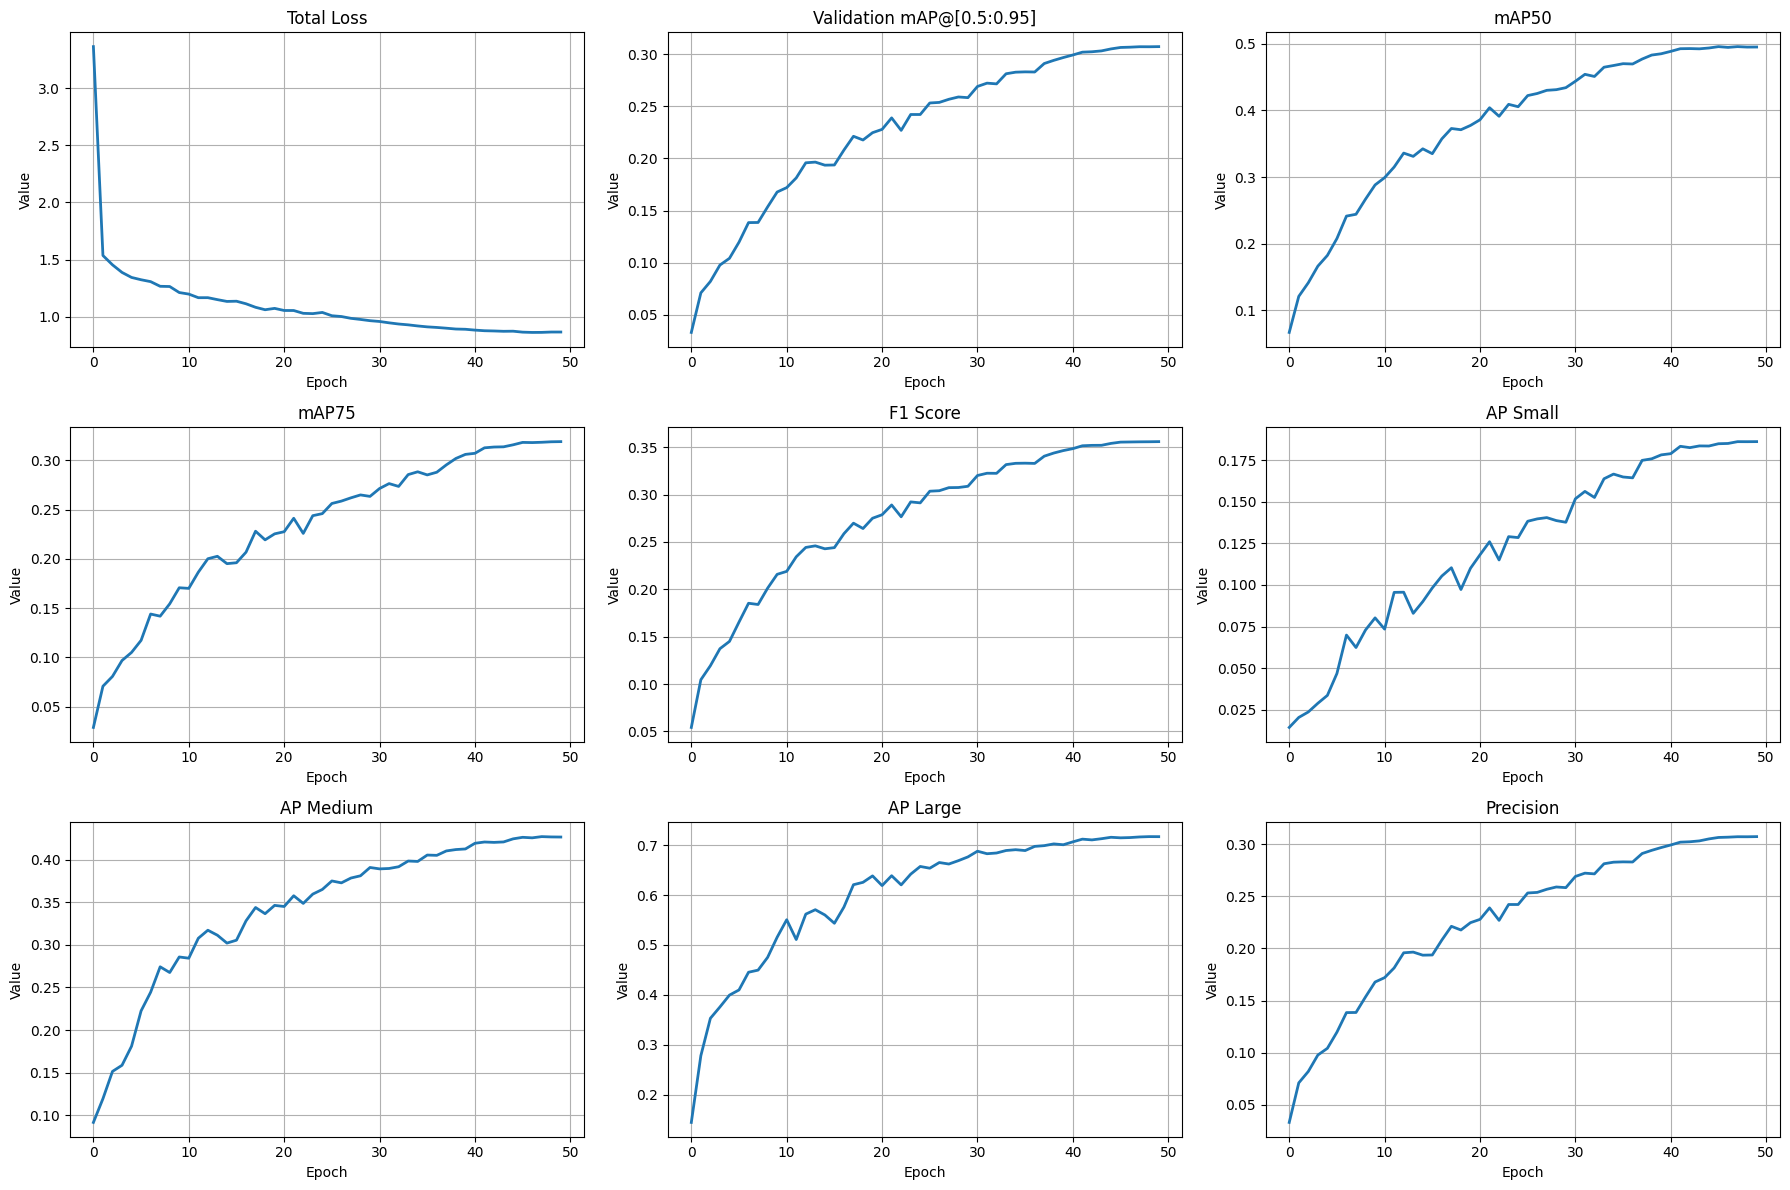

In [4]:
import json
import matplotlib.pyplot as plt
import matplotlib
import os

# --- FIX FONT ---
matplotlib.rcParams.update(matplotlib.rcParamsDefault)

# =====================================================
# 1) Đọc file JSON log
# =====================================================
log_file = "/kaggle/input/datamatcanbang1/training_log.json"
with open(log_file, "r") as f:
    history = json.load(f)

# =====================================================
# 2) Tạo figure với nhiều subplot
# =====================================================
metrics = [
    ("train_loss", "Total Loss"),
    ("val_map", "Validation mAP@[0.5:0.95]"),
    ("val_map50", "mAP50"),
    ("val_map75", "mAP75"),
    ("f1", "F1 Score"),
    ("val_ap_small", "AP Small"),
    ("val_ap_medium", "AP Medium"),
    ("val_ap_large", "AP Large"),
    ("val_precision", "Precision")
]

# Số hàng và cột cho subplot (thay đổi tuỳ số metric)
n_rows = 3
n_cols = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 12))
axes = axes.flatten()

for i, (key, title) in enumerate(metrics):
    if key in history:
        axes[i].plot(history[key], linewidth=2)
        axes[i].set_title(title)
        axes[i].set_xlabel("Epoch")
        axes[i].set_ylabel("Value")
        axes[i].grid(True)
    else:
        axes[i].text(0.5, 0.5, f"{key} not found", ha='center', va='center')
        axes[i].set_axis_off()

plt.tight_layout()
plt.show()

# --- Lưu hình ---
os.makedirs("charts", exist_ok=True)
fig.savefig("charts/all_metrics.png", dpi=200)
